In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# 05 · Synthetic control

A third method. Build a "CBD without the toll" as a weighted average of
other pickup zones, choosing the weights so that it tracks the CBD's weekly
trips during the two pre-toll years (2023-2024). After the toll, the gap
between the real CBD and its synthetic twin is the effect.

Two versions:
* **Standard** (demeaned): the twin matches the CBD's week-to-week ups and
  downs; any trend the donors cannot reproduce carries into the estimate.
* **Trend-adjusted:** every zone's own 2023-2024 trend is removed first,
  the same idea as the trend-adjusted DiD in notebook 03.

Inference: run the same method on every donor zone as if it had been
treated ("placebo in space") and see how unusual the CBD's result is.

In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from congestion.panel import FIRST_POST_WEEK, WINDOW_START, YEAR1_END, load_zone_day, zone_week_panel
from congestion.plots import COLORS, mark_policy, save, style, write_metrics
from congestion.synth import placebo_in_space, placebo_p_value, synthetic_control

style()
lookup = pd.read_csv("data/reference/taxi_zone_lookup.csv").set_index("LocationID")

panel = zone_week_panel(load_zone_day())
panel = panel[(panel["week"] >= WINDOW_START) & (panel["week"] <= YEAR1_END)]
cbd = panel[panel["treated"]].groupby("week")["outcome_trips"].sum()
# Donors: comparison zones with at least 2,000 trips in an average pre-toll week
donors = panel[~panel["treated"] & (panel["pre_mean_trips"] >= 2000)]
wide = np.log(donors.pivot(index="week", columns="pu_zone", values="outcome_trips") + 1)
wide.columns = [str(c) for c in wide.columns]
wide["CBD"] = np.log(cbd)
print(f"{wide.shape[1] - 1} donor zones, {wide.shape[0]} weeks "
      f"({wide.index.min().date()} to {wide.index.max().date()})")

186 donor zones, 154 weeks (2023-01-09 to 2025-12-22)


## 1. Standard synthetic control

In [3]:
std = synthetic_control(wide, "CBD", FIRST_POST_WEEK)
w = std["weights"][std["weights"] > 0.01]
pd.DataFrame({"weight": w.round(3), "zone": lookup["Zone"].reindex(w.index.astype(int)).values,
              "borough": lookup["Borough"].reindex(w.index.astype(int)).values})

,weight,zone,borough
255,0.362,Williamsburg (North Side),Brooklyn
66,0.175,DUMBO/Vinegar Hill,Brooklyn
263,0.138,Yorkville West,Manhattan
106,0.135,Gowanus,Brooklyn
236,0.131,Upper East Side North,Manhattan
166,0.038,Morningside Heights,Manhattan
121,0.021,Hillcrest/Pomonok,Queens


In [4]:
pre_gap = std["path"].loc[std["path"].index < FIRST_POST_WEEK, "gap"]
drift = pre_gap.groupby(pre_gap.index.year).mean()
print(f"Standard: 2025 effect {std['effect_pct']:+.1%}; pre-toll fit error {std['rmspe_pre']:.3f}")
print("Average pre-toll gap by year (should be ~0 every year):", drift.round(3).to_dict())

Standard: 2025 effect -6.7%; pre-toll fit error 0.042
Average pre-toll gap by year (should be ~0 every year): {2023: 0.023, 2024: -0.023}


The standard twin cannot reproduce the CBD's slide in share: its gap is
positive in 2023 and negative in 2024. No combination of other zones lost
trips the way the CBD did, so the drift carries into 2025, and the
standard estimate largely repeats the pre-existing trend.

## 2. Trend-adjusted synthetic control

In [5]:
det = synthetic_control(wide, "CBD", FIRST_POST_WEEK, detrend=True)
print(f"Trend-adjusted: 2025 effect {det['effect_pct']:+.1%}; pre-toll fit error {det['rmspe_pre']:.3f}")
pre_gap_d = det["path"].loc[det["path"].index < FIRST_POST_WEEK, "gap"]
print("Average pre-toll gap by year:", pre_gap_d.groupby(pre_gap_d.index.year).mean().round(3).to_dict())

Trend-adjusted: 2025 effect +0.3%; pre-toll fit error 0.035
Average pre-toll gap by year: {2023: 0.004, 2024: -0.003}


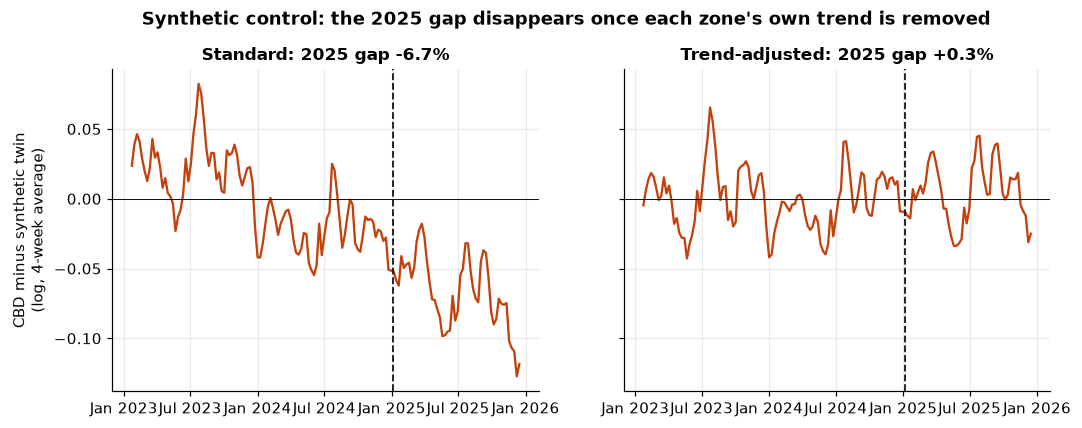

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, r, title in [(axes[0], std, "Standard"), (axes[1], det, "Trend-adjusted")]:
    p = r["path"]
    ax.plot(p.index, p["gap"].rolling(4, center=True).mean(), color=COLORS["cbd"])
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{title}: 2025 gap {r['effect_pct']:+.1%}", fontsize=11)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    mark_policy(ax, label=False)
axes[0].set_ylabel("CBD minus synthetic twin\n(log, 4-week average)")
fig.suptitle("Synthetic control: the 2025 gap disappears once each zone's own trend is removed",
             fontweight="bold", y=1.02)
save(fig, "05_synthetic_gap.png")
plt.show()

## 3. Placebo in space

The p-value is the share of zones (CBD included) whose post-to-pre error
ratio is at least as large as the CBD's, counting only donors whose
pre-toll fit is within five times the CBD's.

Standard: p = 0.18 (186 zones); trend-adjusted: p = 0.93 (186 zones)


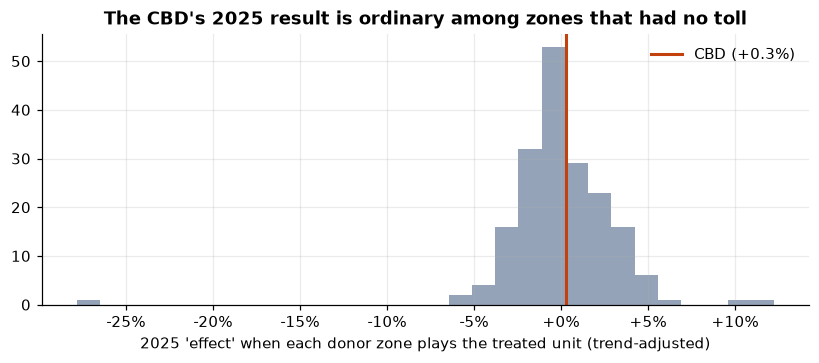

In [7]:
pl_std = placebo_in_space(wide, "CBD", FIRST_POST_WEEK)
pl_det = placebo_in_space(wide, "CBD", FIRST_POST_WEEK, detrend=True)
p_std, p_det = placebo_p_value(pl_std), placebo_p_value(pl_det)
print(f"Standard: p = {p_std:.2f} ({pl_std['kept'].sum()} zones); "
      f"trend-adjusted: p = {p_det:.2f} ({pl_det['kept'].sum()} zones)")

fig, ax = plt.subplots(figsize=(9, 3.2))
kept = pl_det[pl_det["kept"] & ~pl_det["is_treated"]]
ax.hist(kept["effect_pct"], bins=30, color="#94A3B8")
ax.axvline(det["effect_pct"], color=COLORS["cbd"], lw=2, label=f"CBD ({det['effect_pct']:+.1%})")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("2025 'effect' when each donor zone plays the treated unit (trend-adjusted)")
ax.set_title("The CBD's 2025 result is ordinary among zones that had no toll")
ax.legend()
save(fig, "05_placebo_in_space.png")
plt.show()

In [8]:
write_metrics("synth", {
    "n_donors": int(wide.shape[1] - 1),
    "standard_effect_2025": std["effect_pct"],
    "standard_rmspe_pre": std["rmspe_pre"],
    "standard_pre_gap_by_year": {int(k): float(v) for k, v in drift.items()},
    "standard_p_value": p_std,
    "trend_adjusted_effect_2025": det["effect_pct"],
    "trend_adjusted_rmspe_pre": det["rmspe_pre"],
    "trend_adjusted_p_value": p_det,
    "top_weights_standard": {lookup.loc[int(k), "Zone"]: float(v) for k, v in w.head(5).items()},
})

Saved reports/metrics/synth.json
